# 07. Зведене порівняння всіх моделей

Читає `metrics.json` і `history.csv` усіх запусків з `hw2_runs/<модель>/<запуск>/`, нічого не перенавчає. Графіки зберігаються в `images/` для звіту.

Результати Faster R-CNN треба покласти в `hw2_runs/faster_rcnn/<запуск>/` (вихід kernel-ів Соломії).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RUNS = Path.cwd().parent.parent / "hw2_runs"
IMAGES = Path.cwd().parent / "images"
MODELS = ["faster_rcnn", "retinanet", "yolo", "rtdetr"]
COLS = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "mAP_test_like"]

## 1. Усі запуски

In [2]:
rows = {}
for path in sorted(RUNS.glob("*/*/metrics.json")):
    model, run = path.parent.parent.name, path.parent.name
    if run.startswith("smoke") or model not in MODELS:
        continue
    m = json.loads(path.read_text())
    rows[(model, run)] = {**{c: m["val"].get(c) for c in COLS}, "ms/кадр": m.get("ms_per_image")}
runs = pd.DataFrame(rows).T.reindex(MODELS, level=0)
runs.to_csv(RUNS / "all_runs.csv")
runs.astype(float).round(4)

mAP    AP50    AP75  AP_small  AP_medium  \
retinanet baseline         0.1511  0.2926  0.1434    0.0378     0.1482   
          exp1_anchors     0.1432  0.3125  0.1115    0.0519     0.1249   
          exp2_giou        0.1437  0.2848  0.1288    0.0404     0.1196   
yolo      baseline         0.2002  0.3787  0.1860    0.0934     0.1793   
          exp1_imgsz1280   0.1935  0.3816  0.1718    0.1252     0.1975   
          exp2_nwd         0.1683  0.3307  0.1524    0.0950     0.1584   
rtdetr    baseline         0.2385  0.4616  0.2179    0.1239     0.1992   
          exp1_queries500  0.2433  0.4667  0.2228    0.1137     0.2025   
          exp2_giou        0.2360  0.4604  0.2134    0.1105     0.2006   

                           AP_large  mAP_test_like  ms/кадр  
retinanet baseline           0.3018         0.1789  28.4071  
          exp1_anchors       0.2790         0.1530  28.4954  
          exp2_giou          0.3087         0.1650  28.3818  
yolo      baseline           0.3411         0.2322   9.7029  
          exp1_imgsz1280     0.3046         0.2283  13.7074  
          exp2_nwd           0.2848         0.2072   9.6109  
rtdetr    baseline           0.4056         0.2509  49.1369  
          exp1_queries500    0.4204         0.2509  48.9573  
          exp2_giou          0.4109         0.2456  49.2816

## 2. Найкращий запуск кожної моделі і фінальний пайплайн

In [3]:
best = runs.astype(float).groupby(level=0).apply(lambda g: g.loc[g["mAP"].idxmax()]).reindex(MODELS).dropna(how="all")
final_path = RUNS / "pipeline" / "final" / "metrics.json"
if final_path.exists():
    final = json.loads(final_path.read_text())
    best.loc[f"pipeline ({final['model']}, {final['variant']})"] = {c: final["val"].get(c) for c in COLS}
best.round(4)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,mAP_test_like,ms/кадр
retinanet,0.1511,0.2926,0.1434,0.0378,0.1482,0.3018,0.1789,28.4071
yolo,0.2002,0.3787,0.1860,0.0934,0.1793,0.3411,0.2322,9.7029
rtdetr,0.2433,0.4667,0.2228,0.1137,0.2025,0.4204,0.2509,48.9573
"pipeline (yolo11s, tta)",0.2024,0.3837,0.1900,0.0993,0.1784,0.3541,0.2356,NaN


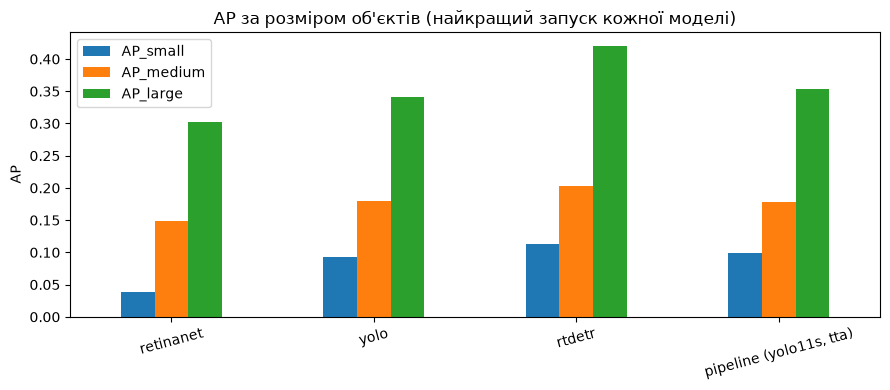

In [4]:
ax = best[["AP_small", "AP_medium", "AP_large"]].plot.bar(figsize=(9, 4), rot=15, title="AP за розміром об'єктів (найкращий запуск кожної моделі)")
ax.set_ylabel("AP")
plt.tight_layout()
plt.savefig(IMAGES / "ap_by_size.png", dpi=120)
plt.show()

## 3. Val mAP за час навчання: RT-DETR проти YOLO (той самий бюджет)

Обидві криві — mAP Ultralytics на кожному 5-му кадрі val після кожної епохи.

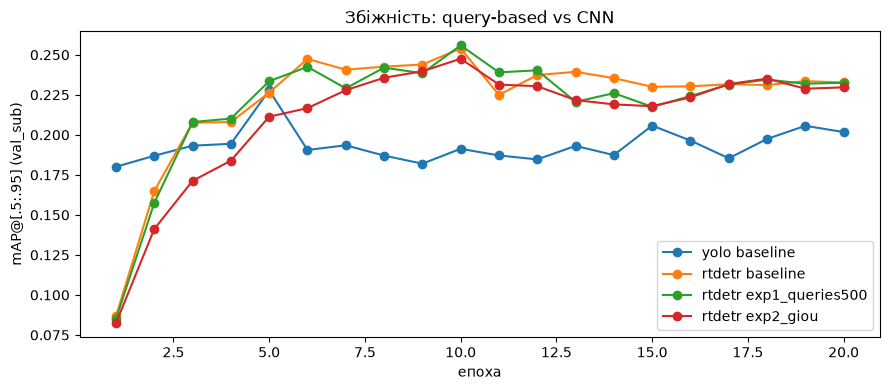

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for model, run in [("yolo", "baseline"), ("rtdetr", "baseline"), ("rtdetr", "exp1_queries500"), ("rtdetr", "exp2_giou")]:
    path = RUNS / model / run / "history.csv"
    if path.exists():
        h = pd.read_csv(path)
        ax.plot(h["epoch"], h["mAP"], marker="o", label=f"{model} {run}")
ax.set(xlabel="епоха", ylabel="mAP@[.5:.95] (val_sub)", title="Збіжність: query-based vs CNN")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "rtdetr_vs_yolo.png", dpi=120)
plt.show()

## 4. Val mAP за епохами: torchvision-моделі

Faster R-CNN і RetinaNet, оцінка `hw2_eval` на кожному 5-му кадрі val.

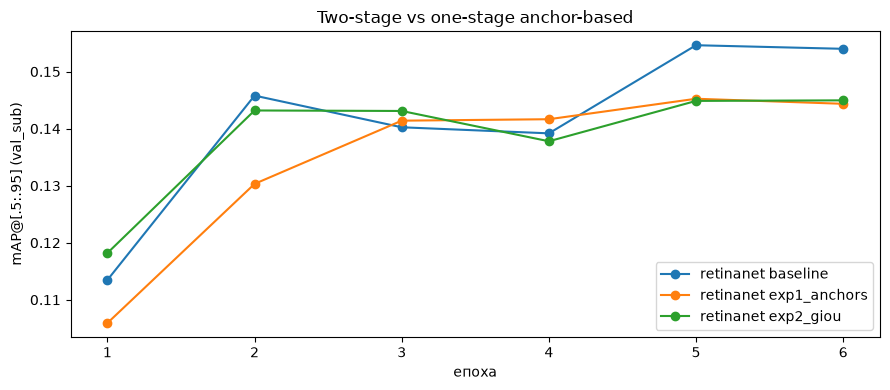

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for model in ("faster_rcnn", "retinanet"):
    for path in sorted((RUNS / model).glob("*/history.csv")):
        if path.parent.name.startswith("smoke"):
            continue
        h = pd.read_csv(path)
        ax.plot(h["epoch"], h["mAP"], marker="o", label=f"{model} {path.parent.name}")
ax.set(xlabel="епоха", ylabel="mAP@[.5:.95] (val_sub)", title="Two-stage vs one-stage anchor-based")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "frcnn_vs_retinanet.png", dpi=120)
plt.show()

## 5. Пайплайн: внесок інференсу і моделі

In [7]:
path = RUNS / "pipeline" / "comparison.csv"
pd.read_csv(path, header=[0, 1], index_col=0).round(4) if path.exists() else "ще немає"

YOLO11s (baseline)                                           \
                              mAP    AP50 AP_small AP_medium mAP_test_like   
base                       0.2002  0.3787   0.0934    0.1793        0.2322   
imgsz+                     0.1926  0.3735   0.0938    0.1892        0.2216   
tta                        0.2024  0.3837   0.0993    0.1784        0.2356   
tiles                      0.2043  0.4028   0.1021    0.1968        0.2305   
tta+temporal               0.1908  0.3493   0.0958    0.1658        0.2237   
tiles+temporal                NaN     NaN      NaN       NaN           NaN   

               YOLO11m                                           
                   mAP    AP50 AP_small AP_medium mAP_test_like  
base            0.1987  0.3815   0.1062    0.1722        0.2080  
imgsz+          0.1962  0.3828   0.1077    0.1885        0.2085  
tta             0.2008  0.3848   0.1043    0.1759        0.2097  
tiles           0.2081  0.4067   0.1195    0.1996        0.2245  
tta+temporal       NaN     NaN      NaN       NaN           NaN  
tiles+temporal  0.2054  0.3954   0.1200    0.1965        0.2224